# Statistical Analysis & Hypothesis Testing

## India Air Quality Intelligence

**Objective:** Apply statistical methods to investigate air quality patterns, measure differences across seasons and cities, identify relationships between variables, and test whether observed differences are statistically significant.

### Analysis Plan
1. Load and validate the cleaned analytical dataset.
2. Calculate descriptive statistics.
3. Examine AQI distributions and variability.
4. Analyse correlations between air quality variables.
5. Conduct hypothesis testing across seasons.
6. Compare AQI levels across selected cities.
7. Calculate confidence intervals and interpret statistical significance.
8. Summarise findings and their implications.

**Study Period:** 2017–2023

**Data Source:** India CPCB-derived air quality dataset.

**Important:** Statistical results describe the available monitoring observations and should be interpreted in light of changing station coverage, missing readings, and potential dependence between hourly observations.

In [1]:
# Import required libraries

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
from scipy.stats import (
    ttest_ind,
    f_oneway,
    mannwhitneyu,
    kruskal,
    pearsonr,
    spearmanr
)

import warnings
warnings.filterwarnings("ignore")

# Visualization settings
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
from pathlib import Path

# Locate the processed dataset
possible_paths = [
    Path.cwd() / "data" / "processed" / "air_quality_analytical.parquet",
    Path.cwd().parent / "data" / "processed" / "air_quality_analytical.parquet"
]

file_path = next(
    (path for path in possible_paths if path.exists()),
    None
)

if file_path is None:
    raise FileNotFoundError(
        "Could not locate air_quality_analytical.parquet"
    )

# Load the dataset
df_analytical = pd.read_parquet(file_path)

print("Dataset loaded successfully!")
print("Shape:", df_analytical.shape)
print("\nColumns:")
print(df_analytical.columns.tolist())

Dataset loaded successfully!
Shape: (13509072, 11)

Columns:
['Station ID', 'State', 'City', 'Station Name', 'Date', 'Hour', 'AQI', 'Timestamp', 'Station', 'AQI_Status', 'AQI_Valid']


In [3]:
# Keep only valid AQI observations
df_valid = df_analytical.dropna(subset=["AQI_Valid"]).copy()

# Use the valid AQI values for statistical analysis
df_valid["AQI"] = df_valid["AQI_Valid"]

print("Statistical dataset ready!")
print("Valid observations:", len(df_valid))
print("Missing AQI values:", df_valid["AQI"].isna().sum())
print("Minimum AQI:", df_valid["AQI"].min())
print("Maximum AQI:", df_valid["AQI"].max())

Statistical dataset ready!
Valid observations: 12473485
Missing AQI values: 0
Minimum AQI: 1.0
Maximum AQI: 500.0


## Descriptive Statistical Analysis

Descriptive statistics help summarize the central tendency, 
dispersion, and distribution of AQI observations.

This section examines:
- Mean, median, and mode
- Standard deviation and variance
- Minimum and maximum AQI
- Quartiles and percentiles
- Distribution shape through skewness and kurtosis

These measures provide an initial understanding of air quality 
levels and their variability across the study period.

In [4]:
# Calculate descriptive statistics

aqi_summary = df_valid["AQI"].describe()

print("OVERALL AQI DESCRIPTIVE STATISTICS")
print("-----------------------------------")
print(aqi_summary)

print("\nADDITIONAL STATISTICAL MEASURES")
print("-----------------------------------")

print("Mean:", round(df_valid["AQI"].mean(), 2))
print("Median:", round(df_valid["AQI"].median(), 2))
print("Mode:", df_valid["AQI"].mode().iloc[0])
print("Variance:", round(df_valid["AQI"].var(), 2))
print("Standard Deviation:", round(df_valid["AQI"].std(), 2))
print("Skewness:", round(df_valid["AQI"].skew(), 3))
print("Kurtosis:", round(df_valid["AQI"].kurtosis(), 3))

OVERALL AQI DESCRIPTIVE STATISTICS
-----------------------------------
count    1.247348e+07
mean     1.364620e+02
std      1.075560e+02
min      1.000000e+00
25%      6.000000e+01
50%      1.000000e+02
75%      1.730000e+02
max      5.000000e+02
Name: AQI, dtype: float64

ADDITIONAL STATISTICAL MEASURES
-----------------------------------
Mean: 136.46
Median: 100.0
Mode: 50.0
Variance: 11568.3
Standard Deviation: 107.56
Skewness: 1.389
Kurtosis: 1.229


### Key Findings — Descriptive Statistics

1. The overall mean AQI was 136.46, while the median was 100.
2. The difference between mean and median indicates a positively skewed distribution.
3. AQI standard deviation was 107.56, indicating considerable variability.
4. Skewness of 1.389 confirms a right-skewed distribution.
5. Excess kurtosis of 1.229 suggests heavier tails than a normal distribution.
6. The interquartile range was 113 (173 - 60), indicating a wide
   spread across the middle 50% of observations.

These findings suggest that AQI observations are not symmetrically
distributed, which should be considered when selecting statistical
tests in subsequent analysis.

## AQI Distribution Analysis

Visualize the distribution of valid AQI observations using
histograms, box plots, and violin plots.

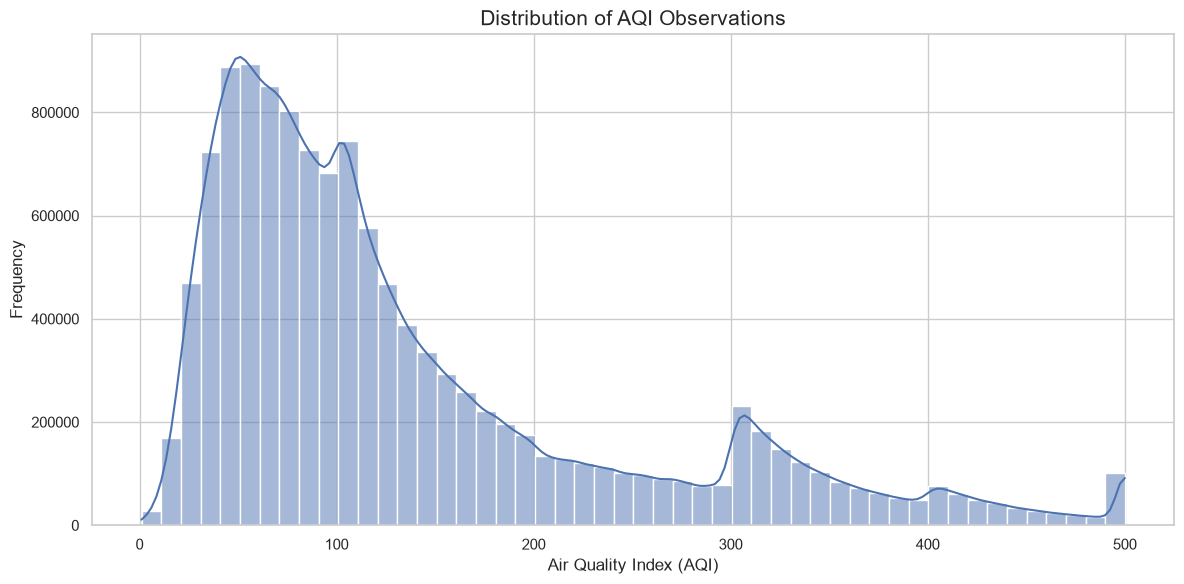

In [5]:
# Histogram with KDE
plt.figure(figsize=(12, 6))

sns.histplot(
    data=df_valid,
    x="AQI",
    bins=50,
    kde=True
)

plt.title("Distribution of AQI Observations", fontsize=15)
plt.xlabel("Air Quality Index (AQI)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

### Interpretation — AQI Distribution Histogram

1. Most AQI observations are concentrated approximately between
   30 and 120.
2. The distribution is positively skewed, with a long right tail.
3. The frequency of observations generally decreases as AQI increases.
4. Noticeable frequency peaks appear around AQI 300 and 400.
5. A spike is also visible at AQI 500, the upper limit of the dataset.

The histogram supports the positive skewness observed in the
descriptive statistics. The unusual peaks and upper-limit
observations require further investigation before drawing conclusions.

In [6]:
# Investigate frequency of important AQI values

values_to_check = [50, 100, 200, 300, 301, 400, 401, 500]

print("FREQUENCY OF SELECTED AQI VALUES")
print("--------------------------------")

for value in values_to_check:
    count = (df_valid["AQI"] == value).sum()
    percentage = (count / len(df_valid)) * 100

    print(
        f"AQI {value}: {count:,} observations "
        f"({percentage:.4f}%)"
    )

# Check observations in the upper AQI ranges
print("\nUPPER AQI RANGE DISTRIBUTION")
print("----------------------------")

for lower, upper in [(290, 300), (301, 310), (390, 400), (401, 410), (490, 500)]:
    count = df_valid["AQI"].between(lower, upper).sum()
    print(f"{lower}-{upper}: {count:,} observations")

FREQUENCY OF SELECTED AQI VALUES
--------------------------------
AQI 50: 108,877 observations (0.8729%)
AQI 100: 84,084 observations (0.6741%)
AQI 200: 20,750 observations (0.1664%)
AQI 300: 15,153 observations (0.1215%)
AQI 301: 24,854 observations (0.1993%)
AQI 400: 6,003 observations (0.0481%)
AQI 401: 9,337 observations (0.0749%)
AQI 500: 87,814 observations (0.7040%)

UPPER AQI RANGE DISTRIBUTION
----------------------------
290-300: 90,007 observations
301-310: 230,680 observations
390-400: 53,303 observations
401-410: 75,877 observations
490-500: 102,035 observations


### Investigation of Unusual AQI Frequencies

The frequency analysis identified several noteworthy patterns:

1. AQI 500 occurred 87,814 times (0.704% of valid observations),
   making it an important value to investigate because it is the
   upper limit of the dataset.
2. AQI 301 occurred more frequently than AQI 300.
3. AQI 401 occurred more frequently than AQI 400.
4. The 490–500 range contained 102,035 observations.

These patterns may reflect AQI reporting characteristics,
measurement distributions, or upper-limit effects. Further
investigation is required before classifying these observations
as anomalies.

For this analysis, AQI 500 remains included because it falls
within the dataset's accepted range of 1–500.

In [7]:
# Filter observations with AQI exactly equal to 500
aqi_500 = df_valid[df_valid["AQI"] == 500].copy()

print("TOTAL AQI 500 OBSERVATIONS:", len(aqi_500))

print("\nTOP 10 CITIES WITH AQI 500")
print("--------------------------")

print(
    aqi_500["City"]
    .value_counts()
    .head(10)
)

print("\nTOP 10 STATIONS WITH AQI 500")
print("----------------------------")

print(
    aqi_500["Station"]
    .value_counts()
    .head(10)
)

print("\nAQI 500 OBSERVATIONS BY YEAR")
print("----------------------------")

print(
    aqi_500["Date"]
    .dt.year
    .value_counts()
    .sort_index()
)

TOTAL AQI 500 OBSERVATIONS: 87814

TOP 10 CITIES WITH AQI 500
--------------------------
City
Delhi           39612
Noida            5303
Ghaziabad        4290
Yamuna Nagar     3869
Faridabad        2713
Mumbai           1907
Lucknow          1802
Patna            1801
Gurugram         1738
Singrauli         918
Name: count, dtype: int64

TOP 10 STATIONS WITH AQI 500
----------------------------
Station
Delhi | Delhi | Anand Vihar Delhi DPCC                    3066
Uttar Pradesh | Ghaziabad | Vasundhara Ghaziabad UPPCB    2138
Delhi | Delhi | Mundka Delhi DPCC                         2120
Delhi | Delhi | Jahangirpuri Delhi DPCC                   1936
Delhi | Delhi | DTU Delhi CPCB                            1879
Delhi | Delhi | Wazirpur Delhi DPCC                       1755
Delhi | Delhi | Punjabi Bagh Delhi DPCC                   1726
Delhi | Delhi | Rohini Delhi DPCC                         1721
Delhi | Delhi | Dwarka-Sector 8 Delhi DPCC                1649
Uttar Pradesh | Noida | Se

### AQI 500 — Geographical and Temporal Investigation

The dataset contains 87,814 valid observations with AQI exactly equal to 500.

Key findings:

1. Delhi contributed 39,612 observations, approximately 45.1% of all AQI 500 readings.
2. Noida and Ghaziabad were the next highest contributors.
3. Anand Vihar Delhi DPCC recorded the highest station-level count (3,066).
4. AQI 500 observations appeared in every year between 2017 and 2023.
5. Raw yearly and city-level counts must be interpreted cautiously
   because monitoring coverage and the total number of valid readings vary.

AQI 500 is retained as a valid recorded value. Its frequency may
indicate an upper-limit or ceiling effect, but the dataset alone
does not establish the underlying reporting mechanism.

## AQI Distribution — Box Plot Analysis

A box plot summarizes the distribution of AQI observations through
the median, quartiles, interquartile range and potential outliers.

This visualization helps identify the spread of AQI readings and
the presence of unusually high observations.

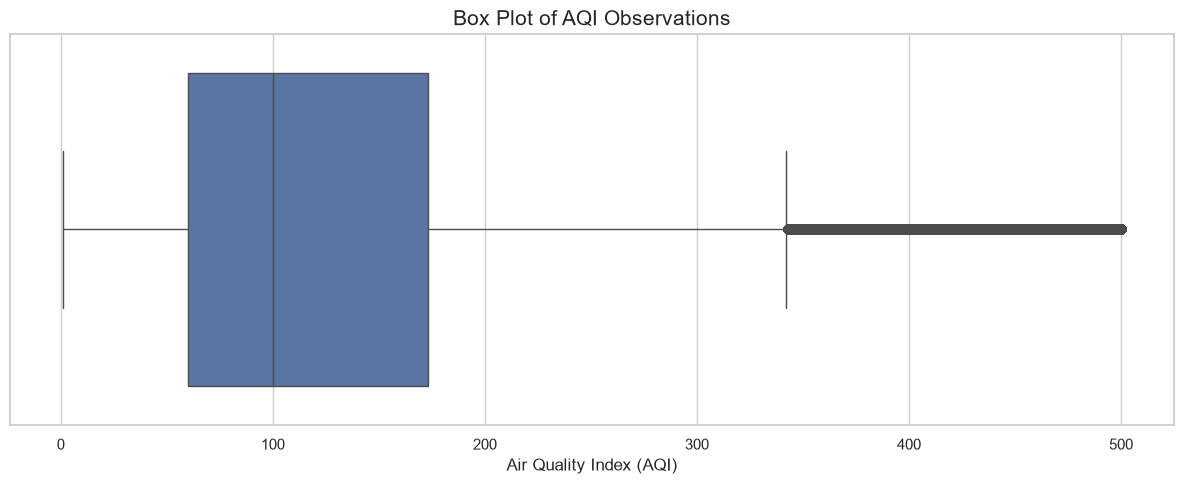

In [8]:
# Box plot of AQI observations

plt.figure(figsize=(12, 5))

sns.boxplot(
    x=df_valid["AQI"],
    showfliers=True
)

plt.title("Box Plot of AQI Observations", fontsize=15)
plt.xlabel("Air Quality Index (AQI)")
plt.tight_layout()
plt.show()

In [9]:
# Calculate IQR and outlier boundaries

Q1 = df_valid["AQI"].quantile(0.25)
Q3 = df_valid["AQI"].quantile(0.75)

IQR = Q3 - Q1

lower_fence = Q1 - 1.5 * IQR
upper_fence = Q3 + 1.5 * IQR

print("INTERQUARTILE RANGE ANALYSIS")
print("----------------------------")
print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower outlier boundary:", lower_fence)
print("Upper outlier boundary:", upper_fence)

# Count potential outliers
lower_outliers = (df_valid["AQI"] < lower_fence).sum()
upper_outliers = (df_valid["AQI"] > upper_fence).sum()

total_outliers = lower_outliers + upper_outliers

print("\nOUTLIER COUNTS")
print("--------------")
print("Lower outliers:", f"{lower_outliers:,}")
print("Upper outliers:", f"{upper_outliers:,}")
print("Total potential outliers:", f"{total_outliers:,}")
print(
    "Percentage of observations:",
    round(total_outliers / len(df_valid) * 100, 2),
    "%"
)

INTERQUARTILE RANGE ANALYSIS
----------------------------
Q1: 60.0
Q3: 173.0
IQR: 113.0
Lower outlier boundary: -109.5
Upper outlier boundary: 342.5

OUTLIER COUNTS
--------------
Lower outliers: 0
Upper outliers: 848,096
Total potential outliers: 848,096
Percentage of observations: 6.8 %


### Interpretation — IQR and Outlier Analysis

The Interquartile Range method was applied to identify potential
statistical outliers.

Key findings:

1. First quartile (Q1): 60.
2. Third quartile (Q3): 173.
3. Interquartile Range (IQR): 113.
4. Upper outlier boundary: 342.5.
5. Lower outlier boundary: -109.5.
6. No lower outliers were identified.
7. A total of 848,096 observations (6.8%) were classified as
   potential upper outliers.

The results indicate a substantial upper tail in the AQI distribution.
These observations are retained because statistical outliers are
not necessarily erroneous measurements.

High AQI observations may represent meaningful pollution episodes
and should not be removed without additional evidence.

## AQI Distribution — Violin Plot Analysis

A violin plot combines box plot statistics with kernel density
estimation to visualize the distribution and concentration
of AQI observations.

It helps identify areas of high observation density,
distribution asymmetry, and variation across AQI values.

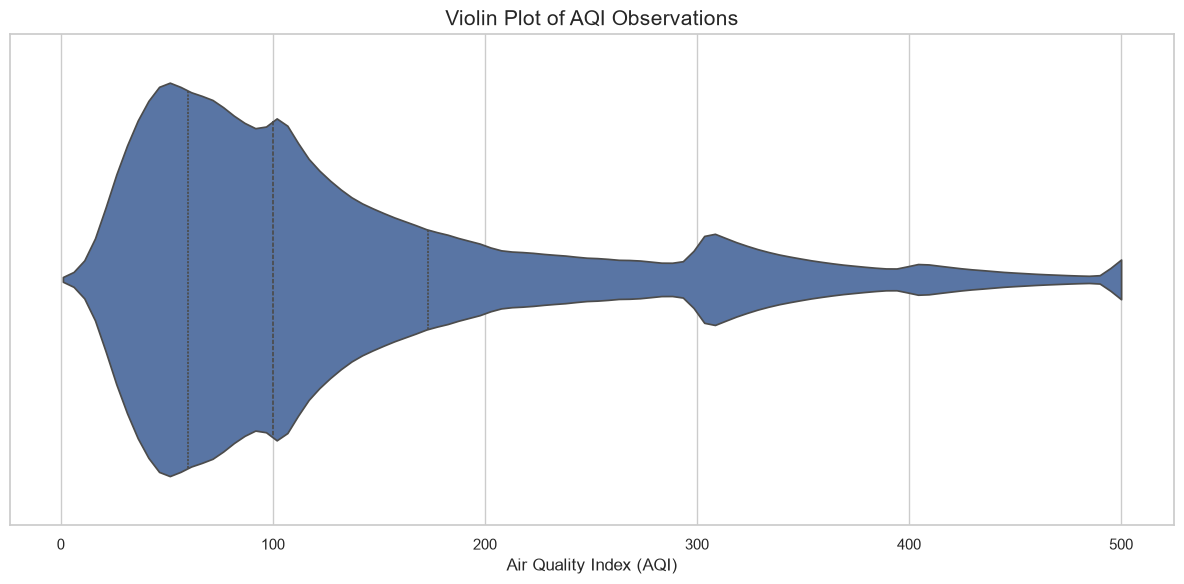

In [10]:
# Violin plot of AQI observations

plt.figure(figsize=(12, 6))

sns.violinplot(
    x=df_valid["AQI"],
    inner="quartile",
    cut=0,
    density_norm="width"
)

plt.title("Violin Plot of AQI Observations", fontsize=15)
plt.xlabel("Air Quality Index (AQI)")
plt.tight_layout()
plt.show()

### Interpretation — AQI Violin Plot

The violin plot provides additional insight into the density
and shape of the AQI distribution.

Key observations:

1. The highest density of observations occurs around AQI 50–60.
2. A second concentration is visible around AQI 100.
3. The distribution has a long upper tail extending towards AQI 500.
4. Additional density peaks appear around AQI 300, 400 and 500.
5. The quartile markers confirm Q1 = 60, Median = 100 and Q3 = 173.

The violin plot reinforces the evidence of positive skewness and
concentration of observations in lower-to-moderate AQI ranges.

KDE smoothing should be considered when interpreting local peaks.

In [11]:
# Extract month and assign seasons

df_valid["Month"] = df_valid["Date"].dt.month

season_mapping = {
    12: "Winter",
    1: "Winter",
    2: "Winter",
    3: "Summer",
    4: "Summer",
    5: "Summer",
    6: "Monsoon",
    7: "Monsoon",
    8: "Monsoon",
    9: "Monsoon",
    10: "Post-Monsoon",
    11: "Post-Monsoon"
}

df_valid["Season"] = df_valid["Month"].map(season_mapping)

print("Season column created successfully!")
print("\nSeason-wise observation counts:")
print(df_valid["Season"].value_counts())

Season column created successfully!

Season-wise observation counts:
Season
Monsoon         4173626
Winter          3079692
Summer          2933894
Post-Monsoon    2286273
Name: count, dtype: int64


## Seasonal AQI Statistical Analysis

This section compares AQI distributions across four seasons:
Winter, Summer, Monsoon, and Post-Monsoon.

We calculate:
- Number of valid observations
- Mean and median AQI
- Standard deviation
- Minimum and maximum AQI
- First and third quartiles

The analysis helps identify seasonal differences in central
tendency and variability.

In [12]:
# Calculate seasonal descriptive statistics

seasonal_stats = (
    df_valid.groupby("Season")["AQI"]
    .agg(
        Observations="count",
        Mean="mean",
        Median="median",
        Std_Dev="std",
        Minimum="min",
        Maximum="max",
        Q1=lambda x: x.quantile(0.25),
        Q3=lambda x: x.quantile(0.75)
    )
    .round(2)
)

# Arrange seasons in chronological order
season_order = [
    "Winter",
    "Summer",
    "Monsoon",
    "Post-Monsoon"
]

seasonal_stats = seasonal_stats.reindex(season_order)

print("SEASONAL AQI DESCRIPTIVE STATISTICS")
print("-----------------------------------")

display(seasonal_stats)

SEASONAL AQI DESCRIPTIVE STATISTICS
-----------------------------------


,Observations,Mean,Median,Std_Dev,Minimum,Maximum,Q1,Q3
Season,,,,,,,,
Winter,3079692,188.96,149.0,121.02,1.0,500.0,91.0,300.0
Summer,2933894,133.22,106.0,92.16,1.0,500.0,69.0,165.0
Monsoon,4173626,81.25,65.0,61.86,1.0,500.0,43.0,101.0
Post-Monsoon,2286273,170.70,127.0,122.63,1.0,500.0,76.0,252.0


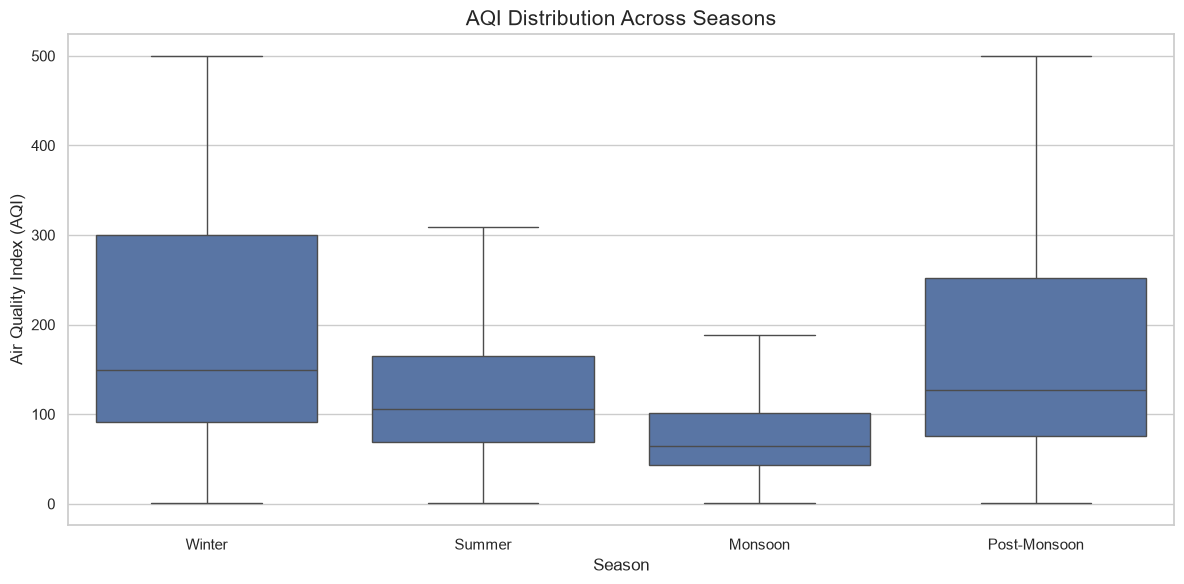

In [13]:
# Compare AQI distributions across seasons

plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df_valid,
    x="Season",
    y="AQI",
    order=season_order,
    showfliers=False
)

plt.title("AQI Distribution Across Seasons", fontsize=15)
plt.xlabel("Season")
plt.ylabel("Air Quality Index (AQI)")
plt.tight_layout()
plt.show()

### Interpretation — Seasonal AQI Statistics

The seasonal descriptive analysis reveals substantial differences
in AQI across the four seasons.

Key findings:

1. Winter recorded the highest mean AQI of 188.96 and median AQI
   of 149.
2. Post-Monsoon recorded the second-highest mean AQI of 170.70.
3. Summer recorded a mean AQI of 133.22.
4. Monsoon recorded the lowest mean AQI of 81.25 and median AQI
   of 65.
5. Post-Monsoon had the highest standard deviation (122.63),
   followed by Winter (121.02).
6. Monsoon had the lowest standard deviation (61.86).

The results indicate considerable seasonal variation in recorded
AQI levels. Winter and Post-Monsoon show higher central AQI levels,
while Monsoon shows comparatively lower levels.

These are pooled observational comparisons. Differences in city,
station coverage and temporal dependence must be considered before
drawing inferential conclusions.

## Statistical Hypothesis Testing — Seasonal Differences

Objective:
Investigate whether AQI differs significantly across the four seasons.

Hypotheses:

H0: Seasonal AQI distributions are equal.

H1: At least one season has a different AQI distribution.

Significance level: 0.05

Methodological consideration:
Hourly AQI observations are temporally dependent and clustered
within monitoring stations and cities. Therefore, inferential
testing will use matched city-level observations rather than
treating every hourly reading as an independent sample.

In [14]:
df_valid["Year"] = df_valid["Date"].dt.year

In [15]:
# Aggregate hourly observations into city-year-season averages

city_season = (
    df_valid.groupby(
        ["State", "City", "Year", "Season"],
        observed=True
    )
    .agg(
        Mean_AQI=("AQI", "mean"),
        Observation_Count=("AQI", "count")
    )
    .reset_index()
)

print("City-season dataset shape:", city_season.shape)
display(city_season.head())

City-season dataset shape: (3468, 6)


,State,City,Year,Season,Mean_AQI,Observation_Count
0,Andhra Pradesh,Amaravati,2017,Winter,197.149284,489
1,Andhra Pradesh,Amaravati,2018,Monsoon,65.384763,2599
2,Andhra Pradesh,Amaravati,2018,Post-Monsoon,107.587588,999
3,Andhra Pradesh,Amaravati,2018,Summer,69.256805,1690
4,Andhra Pradesh,Amaravati,2018,Winter,151.725987,2051


In [16]:
# Count distinct seasons available for each city-year

coverage = (
    city_season.groupby(["State", "City", "Year"])["Season"]
    .nunique()
)

print("City-year combinations with all 4 seasons:",
      (coverage == 4).sum())

print("Total city-year combinations:", len(coverage))

City-year combinations with all 4 seasons: 785
Total city-year combinations: 928


In [17]:
# Step 1: Retain city-year-season groups with at least 500 observations

city_season_filtered = city_season[
    city_season["Observation_Count"] >= 500
].copy()

# Step 2: Identify cities with complete coverage across all 28 combinations

expected_combinations = 7 * 4

city_coverage = (
    city_season_filtered
    .groupby(["State", "City"])
    .size()
    .reset_index(name="Available_Combinations")
)

eligible_cities = city_coverage[
    city_coverage["Available_Combinations"] == expected_combinations
][["State", "City"]]

# Step 3: Create the balanced dataset

balanced_seasonal_data = city_season_filtered.merge(
    eligible_cities,
    on=["State", "City"],
    how="inner"
)

print("BALANCED DATASET VALIDATION")
print("---------------------------")
print("Eligible cities:", len(eligible_cities))
print("Expected combinations:", len(eligible_cities) * 28)
print("Actual combinations:", len(balanced_seasonal_data))
print(
    "Minimum observations per combination:",
    balanced_seasonal_data["Observation_Count"].min()
)

print("\nEligible cities:")
display(eligible_cities)

BALANCED DATASET VALIDATION
---------------------------
Eligible cities: 17
Expected combinations: 476
Actual combinations: 476
Minimum observations per combination: 623

Eligible cities:


,State,City
7,Andhra Pradesh,Visakhapatnam
28,Bihar,Muzaffarpur
29,Bihar,Patna
44,Delhi,Delhi
57,Haryana,Faridabad
59,Haryana,Gurugram
78,Karnataka,Bengaluru
123,Maharashtra,Aurangabad
137,Maharashtra,Mumbai
166,Punjab,Amritsar


In [18]:
# Confirm every eligible city has 28 combinations

check = (
    balanced_seasonal_data
    .groupby(["State", "City"])
    .size()
)

print("All cities have 28 combinations:",
      (check == 28).all())

print("Number of unique cities:", check.size)
print("Total balanced records:", len(balanced_seasonal_data))

All cities have 28 combinations: True
Number of unique cities: 17
Total balanced records: 476


In [19]:
# Average seasonal AQI across the seven years for each city

city_season_avg = (
    balanced_seasonal_data
    .groupby(["State", "City", "Season"])["Mean_AQI"]
    .mean()
    .reset_index()
)

# Create a wide-format repeated-measures dataset

seasonal_pivot = city_season_avg.pivot(
    index=["State", "City"],
    columns="Season",
    values="Mean_AQI"
)

# Arrange seasons consistently
season_order = [
    "Winter",
    "Summer",
    "Monsoon",
    "Post-Monsoon"
]

seasonal_pivot = seasonal_pivot[season_order]

print("REPEATED-MEASURES DATASET")
print("-------------------------")
print("Shape:", seasonal_pivot.shape)
print("Missing values:", seasonal_pivot.isna().sum().sum())

display(seasonal_pivot.round(2))

REPEATED-MEASURES DATASET
-------------------------
Shape: (17, 4)
Missing values: 0


Season                           Winter  Summer  Monsoon  Post-Monsoon
State          City                                                   
Andhra Pradesh Visakhapatnam     161.91   96.60    90.11        118.59
Bihar          Muzaffarpur       309.18  165.26    82.98        216.13
               Patna             301.14  179.99    97.86        228.91
Delhi          Delhi             303.22  198.75   114.88        295.42
Haryana        Faridabad         289.05  184.20   109.39        291.06
               Gurugram          260.53  198.20   133.19        268.97
Karnataka      Bengaluru          90.48   82.33    56.21         79.04
Maharashtra    Aurangabad        122.44  100.99    65.32        105.48
               Mumbai            167.67  107.47    62.60        123.85
Punjab         Amritsar          147.38  104.15    90.23        175.55
               Ludhiana          150.15  111.23    95.76        188.82
               Mandi Gobindgarh  176.92  142.79   102.81        186.62
Rajasthan      Jodhpur           195.96  190.54   127.94        202.93
Telangana      Hyderabad         123.99  100.35    57.13        102.78
Uttar Pradesh  Ghaziabad         329.46  231.06   133.74        316.05
               Noida             305.04  205.59   123.37        298.46
West Bengal    Howrah            232.90   98.83    65.79        154.19

In [20]:
# Validate complete seasonal measurements

assert seasonal_pivot.shape == (17, 4)
assert seasonal_pivot.isna().sum().sum() == 0

print("All 17 cities have four seasonal AQI measurements.")
print("Total matched observations:", seasonal_pivot.size)
print("Validation successful!")

All 17 cities have four seasonal AQI measurements.
Total matched observations: 68
Validation successful!


In [21]:
# Friedman test for repeated seasonal measurements

from scipy.stats import friedmanchisquare

winter = seasonal_pivot["Winter"]
summer = seasonal_pivot["Summer"]
monsoon = seasonal_pivot["Monsoon"]
post_monsoon = seasonal_pivot["Post-Monsoon"]

friedman_stat, friedman_p = friedmanchisquare(
    winter,
    summer,
    monsoon,
    post_monsoon
)

print("FRIEDMAN TEST RESULTS")
print("---------------------")
print(f"Chi-square statistic: {friedman_stat:.4f}")
print(f"P-value: {friedman_p:.10f}")

alpha = 0.05

if friedman_p < alpha:
    print("\nDecision: Reject the null hypothesis.")
    print("At least one season differs significantly.")
else:
    print("\nDecision: Fail to reject the null hypothesis.")
    print("Insufficient evidence of seasonal differences.")

# Calculate Kendall's W effect size
n = len(seasonal_pivot)
k = seasonal_pivot.shape[1]

kendall_w = friedman_stat / (n * (k - 1))

print(f"\nKendall's W effect size: {kendall_w:.4f}")

FRIEDMAN TEST RESULTS
---------------------
Chi-square statistic: 44.7882
P-value: 0.0000000010

Decision: Reject the null hypothesis.
At least one season differs significantly.

Kendall's W effect size: 0.8782


### Friedman Test — Seasonal AQI Differences

A Friedman test was conducted to compare seasonal AQI measurements
across 17 matched cities.

Hypotheses:

H0: Seasonal AQI distributions are equal.
H1: At least one season differs.

Results:

- Number of matched cities: 17
- Number of seasons: 4
- Friedman chi-square statistic: 44.7882
- P-value: approximately 0.000000001
- Significance level: 0.05
- Kendall's W: 0.8782

Conclusion:

The p-value is below the significance threshold of 0.05.
Therefore, the null hypothesis is rejected.

The result provides strong evidence of seasonal differences
in AQI across the matched cities.

Kendall's W of 0.8782 indicates a very large effect size
and strong agreement in seasonal rankings across cities.

The findings apply to the 17 cities selected using the
minimum observation threshold and complete seasonal coverage
criteria. They should not automatically be generalized to
all Indian cities.

In [22]:
# Pairwise Wilcoxon signed-rank tests

from scipy.stats import wilcoxon
from itertools import combinations
from statsmodels.stats.multitest import multipletests

season_names = [
    "Winter",
    "Summer",
    "Monsoon",
    "Post-Monsoon"
]

pairwise_results = []

for season1, season2 in combinations(season_names, 2):

    statistic, p_value = wilcoxon(
        seasonal_pivot[season1],
        seasonal_pivot[season2],
        alternative="two-sided"
    )

    pairwise_results.append({
        "Season_1": season1,
        "Season_2": season2,
        "Wilcoxon_Statistic": statistic,
        "Raw_P_Value": p_value
    })

pairwise_df = pd.DataFrame(pairwise_results)

# Apply Holm correction
reject, corrected_p, _, _ = multipletests(
    pairwise_df["Raw_P_Value"],
    alpha=0.05,
    method="holm"
)

pairwise_df["Holm_Adjusted_P"] = corrected_p
pairwise_df["Significant"] = reject

print("PAIRWISE SEASONAL COMPARISONS")
print("-----------------------------")

display(pairwise_df.round(6))

PAIRWISE SEASONAL COMPARISONS
-----------------------------


,Season_1,Season_2,Wilcoxon_Statistic,Raw_P_Value,Holm_Adjusted_P,Significant
0,Winter,Summer,0.0,0.000015,0.000092,True
1,Winter,Monsoon,0.0,0.000015,0.000092,True
2,Winter,Post-Monsoon,38.0,0.071411,0.071411,False
3,Summer,Monsoon,0.0,0.000015,0.000092,True
4,Summer,Post-Monsoon,2.0,0.000046,0.000092,True
5,Monsoon,Post-Monsoon,0.0,0.000015,0.000092,True


### Pairwise Seasonal Comparisons — Wilcoxon Signed-Rank Test

Following the significant Friedman test, pairwise Wilcoxon
signed-rank tests were conducted across all six seasonal pairs.

Holm correction was applied to control for multiple comparisons.

Results:

1. Winter vs Summer: Significant
   (Adjusted p = 0.000092)

2. Winter vs Monsoon: Significant
   (Adjusted p = 0.000092)

3. Winter vs Post-Monsoon: Not significant
   (Adjusted p = 0.071411)

4. Summer vs Monsoon: Significant
   (Adjusted p = 0.000092)

5. Summer vs Post-Monsoon: Significant
   (Adjusted p = 0.000092)

6. Monsoon vs Post-Monsoon: Significant
   (Adjusted p = 0.000092)

Conclusion:

Five of the six seasonal comparisons showed statistically
significant differences after Holm correction.

Winter and Post-Monsoon were the only pair for which the
difference was not statistically significant at alpha = 0.05.

The findings indicate substantial seasonal variation in AQI
across the 17 matched cities.

In [23]:
# Calculate paired seasonal differences

from itertools import combinations

difference_results = []

for season1, season2 in combinations(season_names, 2):

    differences = (
        seasonal_pivot[season1] - seasonal_pivot[season2]
    )

    difference_results.append({
        "Season_1": season1,
        "Season_2": season2,
        "Median_Difference": differences.median(),
        "Mean_Difference": differences.mean(),
        "Cities_Season1_Higher": (differences > 0).sum(),
        "Cities_Season2_Higher": (differences < 0).sum(),
        "Equal_Cities": (differences == 0).sum()
    })

difference_df = pd.DataFrame(difference_results)

print("MAGNITUDE AND DIRECTION OF SEASONAL DIFFERENCES")
print("------------------------------------------------")

display(difference_df.round(2))

MAGNITUDE AND DIRECTION OF SEASONAL DIFFERENCES
------------------------------------------------


,Season_1,Season_2,Median_Difference,Mean_Difference,Cities_Season1_Higher,Cities_Season2_Higher,Equal_Cities
0,Winter,Summer,62.33,68.77,17,0,0
1,Winter,Monsoon,105.07,121.06,17,0,0
2,Winter,Post-Monsoon,11.44,18.50,11,6,0
3,Summer,Monsoon,44.87,52.30,17,0,0
4,Summer,Post-Monsoon,-50.87,-50.27,1,16,0
5,Monsoon,Post-Monsoon,-88.40,-102.56,0,17,0


### Magnitude and Direction of Seasonal AQI Differences

To understand the direction and magnitude of seasonal variation,
paired AQI differences were calculated across 17 cities.

The difference was calculated as Season 1 AQI minus Season 2 AQI.

Key findings:

1. Winter vs Summer:
   Winter AQI was higher in all 17 cities.
   Median difference: +62.33 AQI points.

2. Winter vs Monsoon:
   Winter AQI was higher in all 17 cities.
   Median difference: +105.07 AQI points.

3. Winter vs Post-Monsoon:
   Winter AQI was higher in 11 cities, while Post-Monsoon
   was higher in 6 cities.
   Median difference: +11.44 AQI points.

4. Summer vs Monsoon:
   Summer AQI was higher in all 17 cities.
   Median difference: +44.87 AQI points.

5. Summer vs Post-Monsoon:
   Post-Monsoon AQI was higher in 16 cities.
   Median difference: -50.87 AQI points.

6. Monsoon vs Post-Monsoon:
   Post-Monsoon AQI was higher in all 17 cities.
   Median difference: -88.40 AQI points.

Overall conclusion:

The analysis indicates a consistent seasonal pattern across
the 17 selected cities:

Winter > Post-Monsoon > Summer > Monsoon

This ordering describes the broad pattern in the city-level
seasonal averages. Winter and Post-Monsoon were not
statistically distinguishable in the pairwise Wilcoxon test.

These findings apply to the selected balanced-city sample,
not necessarily every city in India.

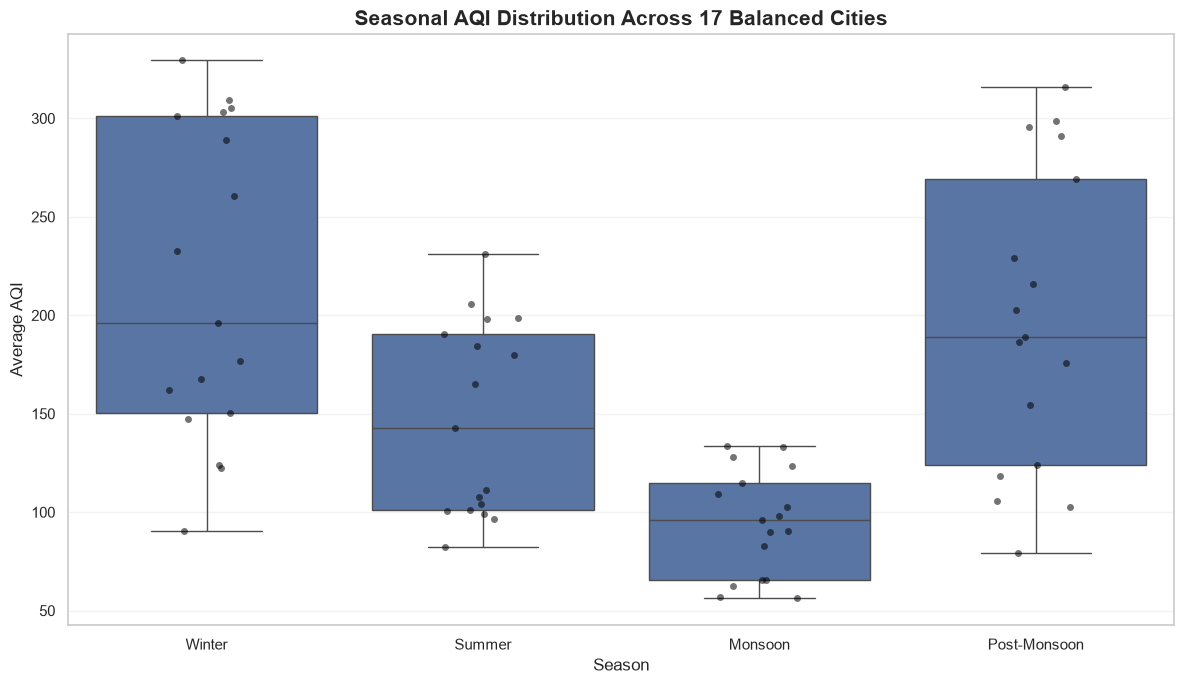

In [24]:
# Prepare data for visualization
plot_data = seasonal_pivot.reset_index().melt(
    id_vars=["State", "City"],
    value_vars=season_order,
    var_name="Season",
    value_name="Mean_AQI"
)

plt.figure(figsize=(12, 7))

sns.boxplot(
    data=plot_data,
    x="Season",
    y="Mean_AQI",
    order=season_order,
    showfliers=False
)

sns.stripplot(
    data=plot_data,
    x="Season",
    y="Mean_AQI",
    order=season_order,
    color="black",
    alpha=0.55,
    size=5,
    jitter=0.15
)

plt.title(
    "Seasonal AQI Distribution Across 17 Balanced Cities",
    fontsize=15,
    fontweight="bold"
)
plt.xlabel("Season")
plt.ylabel("Average AQI")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

### Interpretation: Seasonal AQI Distribution Across 17 Cities

The boxplot and individual city observations reveal the following:

- Winter exhibits the highest median AQI and substantial
  variation across cities.
- Post-Monsoon also shows elevated AQI levels and considerable
  inter-city variation.
- Summer has comparatively lower AQI levels than Winter and
  Post-Monsoon.
- Monsoon exhibits the lowest median AQI and a relatively
  narrower distribution.

The individual observations show that seasonal pollution
patterns are not identical across cities.

The visualization supports the findings of the Friedman and
pairwise Wilcoxon tests.

Winter and Post-Monsoon have relatively similar distributions,
consistent with the statistically non-significant pairwise
comparison between these seasons.

Note: Each point represents one selected city's average AQI
for that season. The chart represents 17 balanced cities,
not all Indian cities.

## Temporal Trend Analysis (2017–2023)

### Objective

This section investigates long-term AQI trends across the
17 cities selected through balanced seasonal coverage.

The analysis aims to:

- Identify increasing or decreasing AQI trends.
- Test whether observed trends are statistically significant.
- Estimate the magnitude of annual AQI changes.
- Compare temporal patterns across cities.

### Statistical methods

1. Mann–Kendall test:
   A non-parametric test used to identify monotonic trends
   in a time series.

2. Sen's slope:
   A robust estimator of the magnitude of a trend,
   expressed as AQI points per year.

### Methodological approach

The analysis uses the balanced dataset containing
17 cities, 7 years, and 4 seasons.

For each city and year, the four seasonal mean AQI values
will be averaged to obtain an annual city-level measure.

This gives each season equal weight in the annual measure,
rather than allowing seasons with more hourly observations
to dominate the calculation.

The analysis covers 2017–2023 and is limited to the
17 selected cities.

In [25]:
# Aggregate seasonal means into annual city-level AQI

city_annual = (
    balanced_seasonal_data
    .groupby(["State", "City", "Year"], as_index=False)
    .agg(
        Annual_Mean_AQI=("Mean_AQI", "mean"),
        Seasonal_Records=("Season", "nunique"),
        Total_Observations=("Observation_Count", "sum")
    )
)

# Sort records
city_annual = city_annual.sort_values(
    ["State", "City", "Year"]
).reset_index(drop=True)

print("CITY ANNUAL DATA")
print("----------------")

print("Shape:", city_annual.shape)
print("Unique cities:", city_annual["City"].nunique())
print("Years:", sorted(city_annual["Year"].unique()))

display(city_annual.head(10))

CITY ANNUAL DATA
----------------
Shape: (119, 6)
Unique cities: 17
Years: [np.int32(2017), np.int32(2018), np.int32(2019), np.int32(2020), np.int32(2021), np.int32(2022), np.int32(2023)]


,State,City,Year,Annual_Mean_AQI,Seasonal_Records,Total_Observations
0,Andhra Pradesh,Visakhapatnam,2017,110.310582,4,6430
1,Andhra Pradesh,Visakhapatnam,2018,124.855138,4,7480
2,Andhra Pradesh,Visakhapatnam,2019,120.449150,4,7144
3,Andhra Pradesh,Visakhapatnam,2020,101.707948,4,7973
4,Andhra Pradesh,Visakhapatnam,2021,110.407729,4,8273
5,Andhra Pradesh,Visakhapatnam,2022,116.036079,4,8372
6,Andhra Pradesh,Visakhapatnam,2023,133.857007,4,7951
7,Bihar,Muzaffarpur,2017,185.323774,4,5679
8,Bihar,Muzaffarpur,2018,228.757600,4,7726
9,Bihar,Muzaffarpur,2019,206.401881,4,6809


In [26]:
# Check whether every city has exactly 7 annual records

annual_coverage = (
    city_annual.groupby(["State", "City"])
    .agg(
        Year_Count=("Year", "nunique"),
        Min_Year=("Year", "min"),
        Max_Year=("Year", "max")
    )
    .reset_index()
)

print("Annual coverage validation")
print("---------------------------")

print("Expected records:", 17 * 7)
print("Actual records:", len(city_annual))
print("All cities have 7 years:",
      (annual_coverage["Year_Count"] == 7).all())
print("All cities cover 2017–2023:",
      (
          (annual_coverage["Min_Year"] == 2017) &
          (annual_coverage["Max_Year"] == 2023)
      ).all())

display(annual_coverage)

Annual coverage validation
---------------------------
Expected records: 119
Actual records: 119
All cities have 7 years: True
All cities cover 2017–2023: True


,State,City,Year_Count,Min_Year,Max_Year
0,Andhra Pradesh,Visakhapatnam,7,2017,2023
1,Bihar,Muzaffarpur,7,2017,2023
2,Bihar,Patna,7,2017,2023
3,Delhi,Delhi,7,2017,2023
4,Haryana,Faridabad,7,2017,2023
5,Haryana,Gurugram,7,2017,2023
6,Karnataka,Bengaluru,7,2017,2023
7,Maharashtra,Aurangabad,7,2017,2023
8,Maharashtra,Mumbai,7,2017,2023
9,Punjab,Amritsar,7,2017,2023


In [27]:
%pip install pymannkendall

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [28]:
import pymannkendall as mk
from statsmodels.stats.multitest import multipletests

In [29]:
trend_results = []

for (state, city), group in city_annual.groupby(["State", "City"]):

    # Sort annual observations chronologically
    group = group.sort_values("Year")

    # Extract annual AQI time series
    aqi_values = group["Annual_Mean_AQI"].values

    # Mann-Kendall test
    result = mk.original_test(aqi_values)

    trend_results.append({
        "State": state,
        "City": city,
        "MK_Trend": result.trend,
        "MK_Tau": result.Tau,
        "MK_P_Value": result.p,
        "Sen_Slope": result.slope,
        "Intercept": result.intercept,
        "MK_Z": result.z
    })

trend_df = pd.DataFrame(trend_results)

print("MANN-KENDALL TREND TEST RESULTS")
print("--------------------------------")

display(trend_df.round(4))

MANN-KENDALL TREND TEST RESULTS
--------------------------------


,State,City,MK_Trend,MK_Tau,MK_P_Value,Sen_Slope,Intercept,MK_Z
0,Andhra Pradesh,Visakhapatnam,no trend,0.2381,0.5480,1.8004,110.6350,0.6008
1,Bihar,Muzaffarpur,no trend,-0.0476,1.0000,-1.2394,193.5907,0.0000
2,Bihar,Patna,no trend,-0.4286,0.2296,-3.8473,215.5689,-1.2015
3,Delhi,Delhi,no trend,-0.5238,0.1331,-2.0039,233.6854,-1.5019
4,Haryana,Faridabad,no trend,-0.5238,0.1331,-4.3939,228.1612,-1.5019
5,Haryana,Gurugram,no trend,-0.3333,0.3675,-11.2213,238.4197,-0.9011
6,Karnataka,Bengaluru,no trend,-0.0476,1.0000,-0.8205,78.9304,0.0000
7,Maharashtra,Aurangabad,no trend,-0.0476,1.0000,-0.7251,103.1024,0.0000
8,Maharashtra,Mumbai,increasing,0.7143,0.0355,4.7399,99.8071,2.1026
9,Punjab,Amritsar,no trend,0.0476,1.0000,0.3896,120.5938,0.0000


In [30]:
# Holm correction across 17 city-level tests

reject, adjusted_p, _, _ = multipletests(
    trend_df["MK_P_Value"],
    alpha=0.05,
    method="holm"
)

trend_df["Adjusted_P_Value"] = adjusted_p
trend_df["Significant"] = reject

# Classify trend direction using the adjusted significance result
trend_df["Final_Trend"] = np.where(
    trend_df["Significant"],
    np.where(
        trend_df["Sen_Slope"] > 0,
        "Increasing",
        "Decreasing"
    ),
    "No Significant Trend"
)

# Sort by Sen's slope
trend_df = trend_df.sort_values(
    "Sen_Slope",
    ascending=True
).reset_index(drop=True)

print("FINAL CITY-WISE TEMPORAL TREND RESULTS")
print("--------------------------------------")

display(
    trend_df[
        [
            "State",
            "City",
            "MK_Tau",
            "MK_P_Value",
            "Adjusted_P_Value",
            "Sen_Slope",
            "Final_Trend"
        ]
    ].round(4)
)

FINAL CITY-WISE TEMPORAL TREND RESULTS
--------------------------------------


,State,City,MK_Tau,MK_P_Value,Adjusted_P_Value,Sen_Slope,Final_Trend
0,Uttar Pradesh,Ghaziabad,-0.9048,0.0069,0.1167,-16.7089,No Significant Trend
1,Rajasthan,Jodhpur,-0.7143,0.0355,0.5680,-11.4542,No Significant Trend
2,Haryana,Gurugram,-0.3333,0.3675,1.0000,-11.2213,No Significant Trend
3,Uttar Pradesh,Noida,-0.6190,0.0715,0.9296,-8.2612,No Significant Trend
4,West Bengal,Howrah,-0.2381,0.5480,1.0000,-4.7328,No Significant Trend
5,Haryana,Faridabad,-0.5238,0.1331,1.0000,-4.3939,No Significant Trend
6,Bihar,Patna,-0.4286,0.2296,1.0000,-3.8473,No Significant Trend
7,Telangana,Hyderabad,-0.7143,0.0355,0.5680,-3.2782,No Significant Trend
8,Delhi,Delhi,-0.5238,0.1331,1.0000,-2.0039,No Significant Trend
9,Bihar,Muzaffarpur,-0.0476,1.0000,1.0000,-1.2394,No Significant Trend


### Interpretation: City-Level Mann-Kendall Trend Analysis

The Mann-Kendall test and Sen's slope estimator were used
to investigate annual AQI trends across 17 balanced cities
during 2017–2023.

Key findings:

1. Four cities had unadjusted p-values below 0.05:
   Ghaziabad, Mumbai, Jodhpur and Hyderabad.

2. Ghaziabad recorded the steepest estimated decreasing
   trend, with a Sen's slope of -16.71 AQI points per year.

3. Mumbai showed an estimated increasing trend of
   approximately 4.74 AQI points per year.

4. After applying Holm correction for 17 simultaneous
   hypothesis tests, none of the city-level trends remained
   statistically significant at alpha = 0.05.

Conclusion:

The analysis identifies directional differences in annual
AQI patterns across cities. However, there is insufficient
statistical evidence to confirm a significant monotonic
trend in any of the 17 cities after multiple-testing correction.

The findings should be interpreted cautiously because the
analysis uses only seven annual observations per city.

A non-significant result does not establish that pollution
levels remained unchanged.

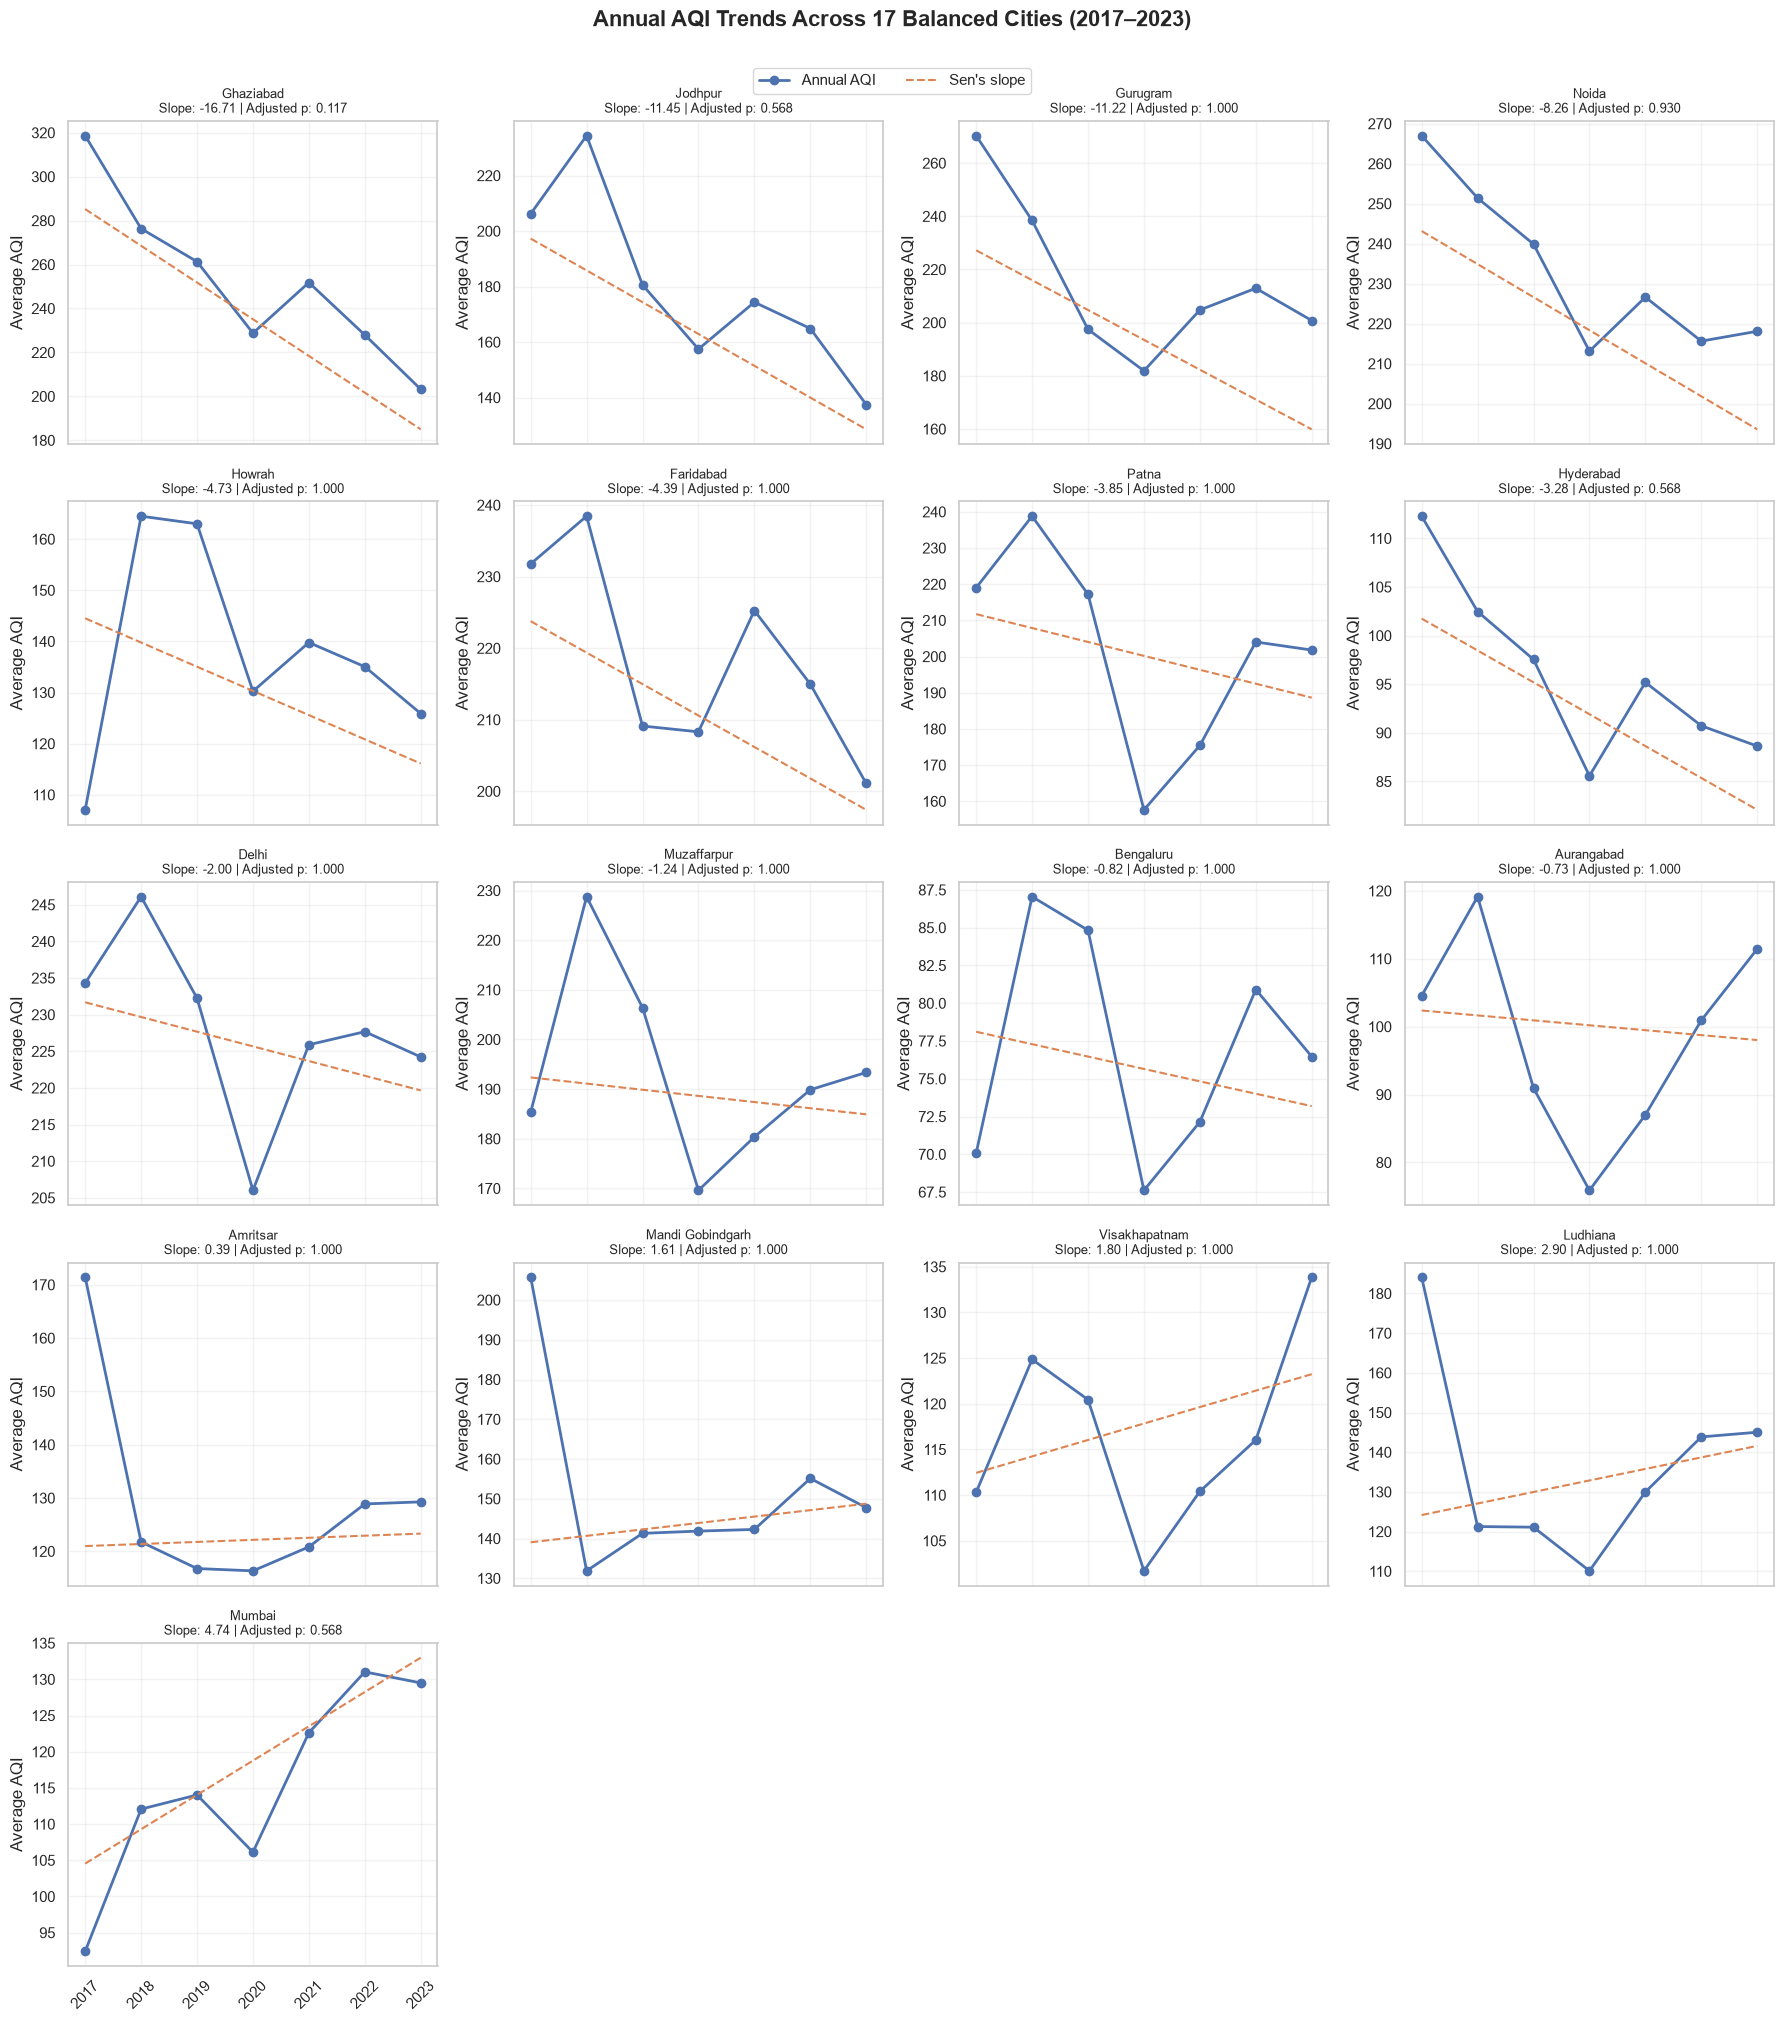

In [31]:
import math

cities = trend_df["City"].tolist()

ncols = 4
nrows = math.ceil(len(cities) / ncols)

fig, axes = plt.subplots(
    nrows,
    ncols,
    figsize=(18, 4 * nrows),
    sharex=True
)

axes = axes.flatten()

for i, city in enumerate(cities):

    ax = axes[i]

    city_data = (
        city_annual[city_annual["City"] == city]
        .sort_values("Year")
    )

    result = trend_df[
        trend_df["City"] == city
    ].iloc[0]

    years = city_data["Year"].values
    aqi = city_data["Annual_Mean_AQI"].values

    # Actual annual AQI
    ax.plot(
        years,
        aqi,
        marker="o",
        linewidth=2,
        label="Annual AQI"
    )

    # Correct Sen's slope line:
    # pymannkendall uses observation positions 1 to 7
    positions = np.arange(1, len(years) + 1)

    sen_line = (
        result["Intercept"] +
        result["Sen_Slope"] * positions
    )

    ax.plot(
        years,
        sen_line,
        linestyle="--",
        label="Sen's slope"
    )

    ax.set_title(
        f'{city}\nSlope: {result["Sen_Slope"]:.2f} | '
        f'Adjusted p: {result["Adjusted_P_Value"]:.3f}',
        fontsize=9
    )

    ax.set_ylabel("Average AQI")
    ax.set_xticks(years)
    ax.tick_params(axis="x", rotation=45)
    ax.grid(alpha=0.25)

# Remove unused panels
for j in range(len(cities), len(axes)):
    fig.delaxes(axes[j])

fig.suptitle(
    "Annual AQI Trends Across 17 Balanced Cities (2017–2023)",
    fontsize=16,
    fontweight="bold",
    y=1.01
)

fig.legend(
    ["Annual AQI", "Sen's slope"],
    loc="upper center",
    bbox_to_anchor=(0.5, 0.985),
    ncol=2
)

plt.tight_layout()
plt.show()

### Interpretation: Annual AQI Trends Across 17 Balanced Cities

The small-multiples visualization compares annual mean AQI
values with estimated Sen's slope lines for 17 cities
between 2017 and 2023.

Key observations:

- Ghaziabad shows a pronounced downward pattern, with an
  estimated Sen's slope of -16.71 AQI points per year.
- Jodhpur and Gurugram also exhibit negative estimated slopes.
- Mumbai shows an upward pattern, with an estimated slope
  of +4.74 AQI points per year.
- Several cities demonstrate substantial year-to-year
  fluctuations rather than smooth directional changes.
- Delhi shows a decline during the earlier years followed
  by a partial increase.

The visualization provides a descriptive comparison of
city-level temporal patterns.

However, none of the 17 city-level trends was statistically
significant after Holm correction.

The dashed lines represent estimated historical trends,
not future AQI forecasts.

In [32]:
# Exploratory lag-1 autocorrelation by city

autocorr_results = []

for (state, city), group in city_annual.groupby(["State", "City"]):

    group = group.sort_values("Year")

    autocorr = group["Annual_Mean_AQI"].autocorr(lag=1)

    autocorr_results.append({
        "State": state,
        "City": city,
        "Lag_1_Autocorrelation": autocorr
    })

autocorr_df = pd.DataFrame(autocorr_results)

autocorr_df = autocorr_df.sort_values(
    "Lag_1_Autocorrelation",
    ascending=False
)

display(autocorr_df.round(3))

,State,City,Lag_1_Autocorrelation
14,Uttar Pradesh,Ghaziabad,0.746
15,Uttar Pradesh,Noida,0.744
5,Haryana,Gurugram,0.663
8,Maharashtra,Mumbai,0.617
13,Telangana,Hyderabad,0.589
12,Rajasthan,Jodhpur,0.527
2,Bihar,Patna,0.373
7,Maharashtra,Aurangabad,0.322
4,Haryana,Faridabad,0.214
3,Delhi,Delhi,0.175


### Autocorrelation Assessment

Lag-1 autocorrelation was calculated for annual AQI values
to investigate potential serial dependence.

Key observations:

- Ghaziabad showed the highest positive autocorrelation (0.746).
- Noida also showed strong positive autocorrelation (0.744).
- Gurugram (0.663), Mumbai (0.617), Hyderabad (0.589)
  and Jodhpur (0.527) also showed positive autocorrelation.
- Mandi Gobindgarh showed negative autocorrelation (-0.628).

Methodological implications:

The conventional Mann-Kendall test assumes independent
observations. Serial correlation may influence the reliability
of its significance tests.

Since the analysis contains only seven annual observations
per city, autocorrelation estimates should be interpreted
as exploratory.

The Mann-Kendall findings are therefore treated as
exploratory rather than definitive evidence of long-term trends.

Further analysis with longer time series would be required
to assess serial dependence and trend significance more
reliably.

## Cross-City AQI Comparison and Variability Analysis

### Objective

Compare pollution levels and AQI variability across the
17 balanced cities.

The analysis will examine:

- Average and median AQI.
- Standard deviation and interquartile range.
- Coefficient of variation.
- Relative consistency of AQI across cities.

Each city has 28 year-season observations covering
2017–2023 and all four seasons.

In [33]:
# City-level pollution and variability profiles

city_profiles = (
    balanced_seasonal_data
    .groupby(["State", "City"])
    .agg(
        Mean_AQI=("Mean_AQI", "mean"),
        Median_AQI=("Mean_AQI", "median"),
        Std_AQI=("Mean_AQI", "std"),
        Min_AQI=("Mean_AQI", "min"),
        Max_AQI=("Mean_AQI", "max"),
        Q1=("Mean_AQI", lambda x: x.quantile(0.25)),
        Q3=("Mean_AQI", lambda x: x.quantile(0.75)),
        Observations=("Mean_AQI", "count")
    )
    .reset_index()
)

# Calculate interquartile range
city_profiles["IQR"] = (
    city_profiles["Q3"] - city_profiles["Q1"]
)

# Calculate coefficient of variation
city_profiles["CV_Percent"] = (
    city_profiles["Std_AQI"] /
    city_profiles["Mean_AQI"]
) * 100

# Rank cities by average AQI
city_profiles = city_profiles.sort_values(
    "Mean_AQI",
    ascending=False
).reset_index(drop=True)

print("CROSS-CITY AQI AND VARIABILITY PROFILE")
print("--------------------------------------")

display(city_profiles.round(2))

CROSS-CITY AQI AND VARIABILITY PROFILE
--------------------------------------


,State,City,Mean_AQI,Median_AQI,Std_AQI,Min_AQI,Max_AQI,Q1,Q3,Observations,IQR,CV_Percent
0,Uttar Pradesh,Ghaziabad,252.58,262.14,90.22,113.13,412.32,163.37,321.50,28,158.13,35.72
1,Uttar Pradesh,Noida,233.11,253.46,80.86,106.58,342.46,140.25,305.54,28,165.29,34.69
2,Delhi,Delhi,228.07,255.62,81.44,99.17,327.53,130.85,302.39,28,171.54,35.71
3,Haryana,Faridabad,218.43,237.55,81.29,88.18,333.94,135.09,290.90,28,155.81,37.22
4,Haryana,Gurugram,215.22,245.69,65.21,94.87,311.67,168.71,253.66,28,84.96,30.30
5,Bihar,Patna,201.98,199.53,81.99,62.33,352.40,124.08,264.97,28,140.89,40.59
6,Bihar,Muzaffarpur,193.38,185.92,87.59,60.76,350.10,121.06,272.91,28,151.85,45.29
7,Rajasthan,Jodhpur,179.34,180.35,47.40,92.15,278.69,151.99,201.99,28,50.00,26.43
8,Punjab,Mandi Gobindgarh,152.28,161.56,43.99,81.89,282.27,125.35,174.87,28,49.53,28.89
9,West Bengal,Howrah,137.93,107.56,71.78,48.75,281.66,83.90,203.03,28,119.13,52.04


### Cross-City Pollution and Variability Analysis

The city-level analysis compares average AQI and pollution variability
across 17 cities with balanced seasonal coverage from 2017 to 2023.

Key findings:

1. Ghaziabad recorded the highest average AQI (252.58), followed by
   Noida (233.11) and Delhi (228.07).

2. Bengaluru recorded the lowest average AQI (77.01), followed by
   Hyderabad (96.06) and Aurangabad (98.56).

3. Ghaziabad showed the highest standard deviation (90.22), indicating
   substantial variation across its seasonal-year averages.

4. Howrah had the highest coefficient of variation (52.04%), suggesting
   considerable relative variability despite a lower average AQI than
   the most polluted cities.

5. Bengaluru showed the lowest standard deviation (15.62), indicating
   comparatively consistent seasonal-year AQI averages.

These comparisons are descriptive and apply to the 17 selected cities.
They should not be interpreted as a complete ranking of all Indian cities.

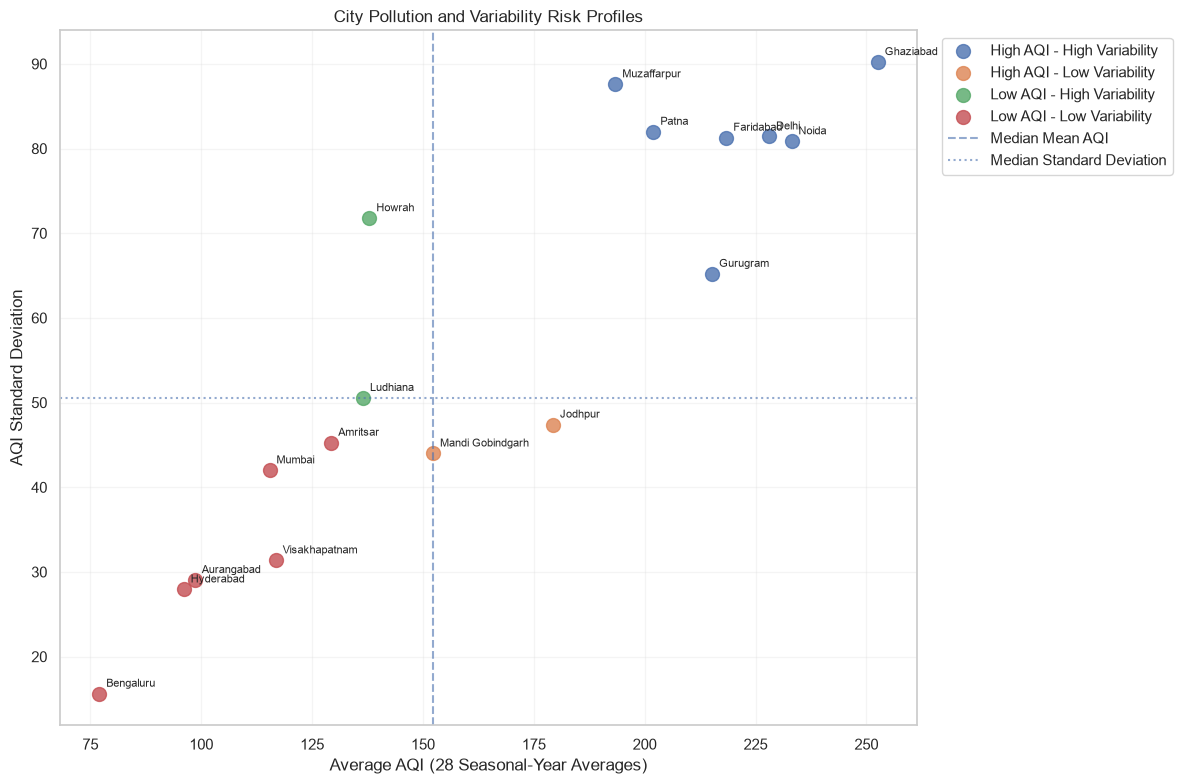

CITY PROFILE DISTRIBUTION


,Profile,City_Count
0,High AQI - High Variability,7
1,Low AQI - Low Variability,6
2,High AQI - Low Variability,2
3,Low AQI - High Variability,2


In [34]:
# Median thresholds for project-specific classification
mean_threshold = city_profiles["Mean_AQI"].median()
std_threshold = city_profiles["Std_AQI"].median()

# Classify cities into four profiles
def classify_city(row):
    high_aqi = row["Mean_AQI"] >= mean_threshold
    high_variability = row["Std_AQI"] >= std_threshold

    if high_aqi and high_variability:
        return "High AQI - High Variability"
    elif high_aqi and not high_variability:
        return "High AQI - Low Variability"
    elif not high_aqi and high_variability:
        return "Low AQI - High Variability"
    else:
        return "Low AQI - Low Variability"

city_profiles["City_Profile"] = city_profiles.apply(
    classify_city, axis=1
)

# Scatter plot
plt.figure(figsize=(12, 8))

for profile in city_profiles["City_Profile"].unique():
    subset = city_profiles[
        city_profiles["City_Profile"] == profile
    ]

    plt.scatter(
        subset["Mean_AQI"],
        subset["Std_AQI"],
        s=100,
        label=profile,
        alpha=0.8
    )

    for _, row in subset.iterrows():
        plt.annotate(
            row["City"],
            (row["Mean_AQI"], row["Std_AQI"]),
            xytext=(5, 5),
            textcoords="offset points",
            fontsize=8
        )

plt.axvline(
    mean_threshold,
    linestyle="--",
    alpha=0.6,
    label="Median Mean AQI"
)

plt.axhline(
    std_threshold,
    linestyle=":",
    alpha=0.6,
    label="Median Standard Deviation"
)

plt.title("City Pollution and Variability Risk Profiles")
plt.xlabel("Average AQI (28 Seasonal-Year Averages)")
plt.ylabel("AQI Standard Deviation")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

print("CITY PROFILE DISTRIBUTION")
display(
    city_profiles["City_Profile"]
    .value_counts()
    .rename_axis("Profile")
    .reset_index(name="City_Count")
)

### City Pollution and Variability Risk Profiling

Cities were classified into four analytical profiles using the median
of their average AQI and standard deviation across 28 seasonal-year
averages.

Key findings:

- 7 cities belong to the High AQI–High Variability group.
- 2 cities belong to the High AQI–Low Variability group.
- 2 cities belong to the Low AQI–High Variability group.
- 6 cities belong to the Low AQI–Low Variability group.

Ghaziabad, Noida, Delhi, Faridabad, Gurugram, Patna and Muzaffarpur
fall into the High AQI–High Variability group.

Howrah and Ludhiana demonstrate that relatively lower average AQI
does not necessarily imply low variability.

This classification is exploratory and uses sample-specific median
thresholds. It is not an official pollution-risk classification.

In [35]:
from scipy.stats import pearsonr, spearmanr

# Relationship between average AQI and variability
x = city_profiles["Mean_AQI"]
y = city_profiles["Std_AQI"]

pearson_corr, pearson_p = pearsonr(x, y)
spearman_corr, spearman_p = spearmanr(x, y)

print("CORRELATION: AVERAGE AQI VS VARIABILITY")
print("---------------------------------------")

print(f"Pearson correlation: {pearson_corr:.4f}")
print(f"Pearson p-value: {pearson_p:.6f}")

print(f"\nSpearman correlation: {spearman_corr:.4f}")
print(f"Spearman p-value: {spearman_p:.6f}")

CORRELATION: AVERAGE AQI VS VARIABILITY
---------------------------------------
Pearson correlation: 0.9036
Pearson p-value: 0.000001

Spearman correlation: 0.8897
Spearman p-value: 0.000002


### Correlation Analysis: Average AQI vs Pollution Variability

Pearson and Spearman correlation tests were conducted to examine
the relationship between city-level average AQI and standard deviation.

Results:

- Pearson correlation coefficient: 0.9036
- Pearson p-value: 0.000001
- Spearman correlation coefficient: 0.8897
- Spearman p-value: 0.000002

Both methods indicate a very strong positive association between
average AQI and pollution variability across the 17 selected cities.

The similar Pearson and Spearman coefficients suggest that this
relationship is evident in both the raw values and city rankings.

Business implication:

Cities with higher average AQI also tend to show greater variation
across seasonal-year averages. Therefore, pollution monitoring
should consider both average pollution intensity and variability.

Limitations:

This is a city-level exploratory analysis based on 17 selected cities.
Correlation does not establish causation, and the results should not
be generalized to every Indian city.

In [36]:
# Leave-one-city-out Pearson correlation sensitivity analysis

from scipy.stats import pearsonr
import pandas as pd

sensitivity_results = []

for city in city_profiles["City"]:

    temp = city_profiles[
        city_profiles["City"] != city
    ]

    corr, p_value = pearsonr(
        temp["Mean_AQI"],
        temp["Std_AQI"]
    )

    sensitivity_results.append({
        "Excluded_City": city,
        "Pearson_Correlation": corr,
        "P_Value": p_value
    })

sensitivity_df = pd.DataFrame(sensitivity_results)

display(
    sensitivity_df.sort_values(
        "Pearson_Correlation"
    ).round(4)
)

print("Original Pearson correlation:", round(pearson_corr, 4))
print(
    "Minimum correlation after excluding one city:",
    round(sensitivity_df["Pearson_Correlation"].min(), 4)
)
print(
    "Maximum correlation after excluding one city:",
    round(sensitivity_df["Pearson_Correlation"].max(), 4)
)

,Excluded_City,Pearson_Correlation,P_Value
16,Bengaluru,0.8835,0.0
0,Ghaziabad,0.8897,0.0
15,Hyderabad,0.8931,0.0
14,Aurangabad,0.8939,0.0
2,Delhi,0.8965,0.0
3,Faridabad,0.8969,0.0
1,Noida,0.8979,0.0
12,Visakhapatnam,0.8991,0.0
13,Mumbai,0.9019,0.0
11,Amritsar,0.9021,0.0


Original Pearson correlation: 0.9036
Minimum correlation after excluding one city: 0.8835
Maximum correlation after excluding one city: 0.9402



### Interpretation: Average AQI and Pollution Variability

The cross-city analysis reveals a very strong positive association between average AQI and AQI variability.

- Pearson correlation: 0.9036 (p = 0.000001).
- Spearman correlation: 0.8897 (p = 0.000002).
- Leave-one-city-out Pearson correlations ranged from 0.8835 to 0.9402.

The agreement between Pearson and Spearman correlations indicates that the positive association is evident in both linear relationships and city rankings.

The sensitivity analysis further demonstrates that the relationship remains strong even after excluding individual cities, suggesting that the observed association is not driven by a single influential city.

**Business and environmental interpretation:** Cities experiencing higher average pollution levels also tend to experience greater fluctuations in AQI. This may indicate a greater need for consistent air-quality monitoring and targeted pollution-management strategies.

**Statistical limitation:** The analysis is based on 17 selected cities with balanced seasonal coverage. The findings describe an association at the city level and should not be interpreted as evidence of causation or generalized automatically to all Indian cities.


In [37]:

import numpy as np
from scipy.stats import norm

# Extract paired city-level values
x = city_profiles["Mean_AQI"].to_numpy()
y = city_profiles["Std_AQI"].to_numpy()

# Sample size and Pearson correlation
n = len(x)
r = np.corrcoef(x, y)[0, 1]

# Fisher z transformation
z = np.arctanh(r)
standard_error = 1 / np.sqrt(n - 3)

# 95% confidence interval
z_critical = norm.ppf(0.975)

z_lower = z - z_critical * standard_error
z_upper = z + z_critical * standard_error

ci_lower = np.tanh(z_lower)
ci_upper = np.tanh(z_upper)

print("PEARSON CORRELATION CONFIDENCE INTERVAL")
print("---------------------------------------")
print(f"Number of cities: {n}")
print(f"Pearson correlation: {r:.4f}")
print(f"95% Confidence Interval: ({ci_lower:.4f}, {ci_upper:.4f})")


PEARSON CORRELATION CONFIDENCE INTERVAL
---------------------------------------
Number of cities: 17
Pearson correlation: 0.9036
95% Confidence Interval: (0.7477, 0.9651)



### Confidence Interval: Average AQI vs Pollution Variability

To quantify uncertainty around the Pearson correlation, a 95% confidence interval was calculated using Fisher's z-transformation.

**Results:**
- Number of cities: 17
- Pearson correlation: 0.9036
- 95% confidence interval: 0.7477 to 0.9651

The confidence interval remains entirely above zero, reinforcing the evidence of a strong positive association between average AQI and pollution variability.

Although the interval supports a substantial relationship, its width reflects the uncertainty associated with a relatively small sample of 17 cities.

**Conclusion:** Across the selected balanced cities, higher average AQI tends to be associated with greater AQI variability. This finding can help identify cities that may require more consistent air-quality monitoring and targeted interventions.

**Limitation:** The confidence interval relies on assumptions including independent city-level observations and an approximately suitable sampling model. The results should not be generalized automatically to all Indian cities.
